In [1]:
import torch
import torch.nn as nn
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from tqdm import tqdm
import random
import torchvision.transforms.functional as F
from PIL import Image
import numpy as np
from utils import moving_average
from IPython.display import clear_output
import os

In [2]:
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"

print(f"Using device: {device}")

# Choisir le GPU et vérifier
torch.cuda.set_device(1)
print(torch.cuda.current_device())  # doit afficher le numéro choisi dans torch.cuda.set_device()
print(torch.cuda.get_device_name(torch.cuda.current_device()))

Using device: cuda
1
Tesla V100S-PCIE-32GB


In [3]:
batch_size = 512
learning_rate = 3e-4
n_epochs = 10
crop_size = 32
img_channels = 3
n_classes = 16

In [4]:
class ImageDataset(Dataset):

    def __init__(self, split, transform=None):
        self.split = split
        self.transform = transform


    def __len__(self):
        files = [f for f in os.listdir(f"data/dataset_crops_paires/{self.split}/sat/")]
        return len(files)
    

    def data_augm_pair(self, img1, img2):
        # flip horizontal
        if random.random() > 0.5:
            img1 = F.hflip(img1)
            img2 = F.hflip(img2)

        # flip vertical
        if random.random() > 0.5:
            img1 = F.vflip(img1)
            img2 = F.vflip(img2)

        # rotation
        angles = [0, 90, 180, 270]
        angle = random.choice(angles)
        img1 = F.rotate(img1, angle)
        img2 = F.rotate(img2, angle)

        return img1, img2


    def __getitem__(self, idx):
        crop = Image.open(f"data/dataset_crops_paires/{self.split}/sat/crop_{idx}.png").convert("RGB")
        crop_ann = Image.open(f"data/dataset_crops_paires/{self.split}/ann/crop_{idx}.png").convert("RGB")

        cropped_tensor = transforms.ToTensor()(crop)
        cropped_tensor_ann = transforms.ToTensor()(crop_ann)

        if self.transform:
            cropped_tensor = self.transform(cropped_tensor)
            cropped_tensor, cropped_tensor_ann = self.data_augm_pair(cropped_tensor, cropped_tensor_ann)

        return cropped_tensor, cropped_tensor_ann


transform = transforms.Compose([
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5]),
])

train_dataset = ImageDataset(split="train", transform=transform)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=8)

val_dataset = ImageDataset(split="val", transform=transform)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=True, num_workers=8)

train_iterator = iter(train_loader)
val_iterator = iter(val_loader)

In [5]:
# import matplotlib.pyplot as plt

# for i in range(3):
#     img1, img2, *_ = next(iter(train_loader)) 

#     # On prend le premier élément du batch
#     img1 = img1[0].permute(1, 2, 0).numpy()
#     img2 = img2[0].permute(1, 2, 0).numpy()

#     # Les images sont souvent normalisées, on remet dans [0,1]
#     img1 = (img1 + 1) / 2

#     plt.figure(figsize=(10, 5))
#     plt.subplot(1, 2, 1)
#     plt.imshow(img1)
#     plt.subplot(1, 2, 2)
#     plt.imshow(img2)
#     plt.show()

In [6]:
from torchvision.models import resnet18
from torchvision.models import ResNet18_Weights   # Import des poids officiels

resnet = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)   # Charger un modèle préentraîné
resnet = nn.Sequential(*list(resnet.children())[:-2])    # enlever les couches avgpool : AdaptiveAvgPool2d(output_size=(1, 1)) et fc : Linear(in_features=512, out_features=1000, bias=True)

# ajouter une couche de deconvolution à la fin
decoder = nn.ConvTranspose2d(in_channels=512, out_channels=n_classes, kernel_size=32, stride=32)  # stride=32 pour remonter de H/32 -> H
model = nn.Sequential(
    resnet,
    decoder
)

# # différentes couches du modèle
# for name, layer in model.named_children():
#     print(name, ":", layer)

In [7]:
model = model.to(device)   # model.to(device) et pas model().to(device) car ici le model est déjà instancié
# optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)
optimizer = torch.optim.AdamW(decoder.parameters(), lr=learning_rate)
criterion = nn.CrossEntropyLoss()

total_params = sum(p.numel() for p in model.parameters())
print(f"Total parameters in the model: {total_params/1e6:.6f} million")

train_loss_list, val_loss_list, test_loss_list = [], [], []

Total parameters in the model: 19.565136 million


In [8]:
def imgs_to_niveaucouleur(imgs):

    imgs = (imgs * 255).byte()

    imgs = imgs.permute(1, 0, 2, 3)   # (B, C, H, W) -> (C, B, H, W)

    colors = [[57, 125, 73], [65, 155, 223], [122, 135, 198], [136, 176, 83], [196, 40, 27], [223, 195, 90], [228, 150, 53], [13, 253, 21], [165, 244, 167], [65, 166, 68], [16, 114, 20], [242, 34, 214], [207, 128, 253], [145, 64, 206], [84, 19, 121]]

    masks = []
    for c in colors:
        color_tensor = torch.tensor(c, dtype=imgs.dtype, device=imgs.device).view(-1, 1, 1, 1)
        mask = (imgs == color_tensor).all(dim=0)
        masks.append(mask)

    # # Combiner tous les masks
    # combined_mask = masks[0].clone()
    # for m in masks[1:]:
    #     combined_mask |= m  # ou “torch.logical_or(combined_mask, m)”

    # # Vérifier les pixels qui ne correspondent à aucune couleur
    # unknown_pixels = ~combined_mask
    # n_unknown = unknown_pixels.sum().item()

    # print(f"Nombre de pixels inconnus : {n_unknown}")

    out = torch.zeros((imgs.shape[1], imgs.shape[2], imgs.shape[3]), dtype=torch.int64, device=imgs.device)
    for i, mask in enumerate(masks):
        out[mask] = i + 1

    return out

moyenne sur les 100 dernières valeurs:   train_loss: 1.5253759622573853   val_loss: 1.432301640510559


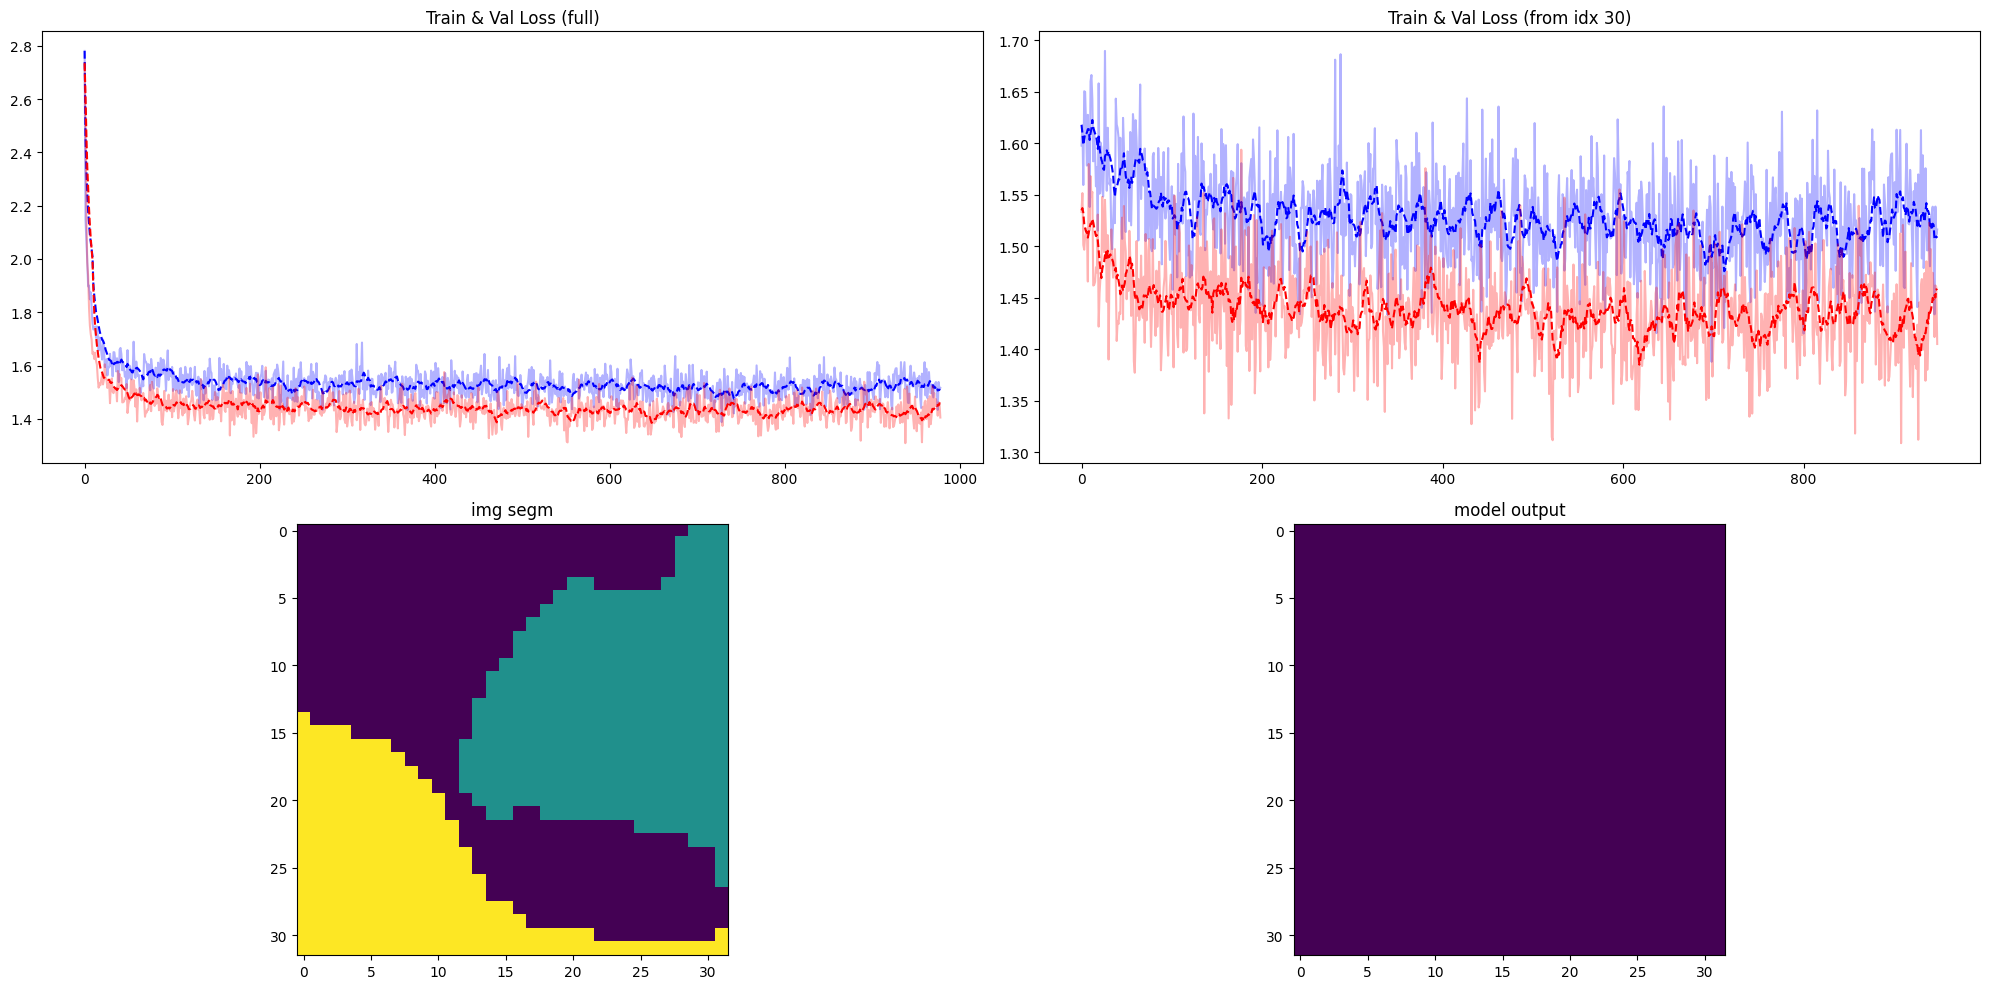

In [ ]:
for epoch in range(n_epochs):
    for i, (imgs, imgs_segm) in tqdm(enumerate(train_loader), total=len(train_loader)):

        imgs, imgs_segm = imgs.to(device), imgs_segm.to(device)
        imgs_segm = imgs_to_niveaucouleur(imgs_segm)

        output = model(imgs)
        loss = criterion(output, imgs_segm)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()



        # if epoch % 10 == 0 and i % 999 == 0:
        if i % 10 == 0:

            train_loss_list.append(loss.item())

            # get val loss
            model.eval()
            with torch.no_grad():
                try:
                    imgs, imgs_segm = next(val_iterator)
                except StopIteration:
                    val_iterator = iter(val_loader)
                    imgs, imgs_segm = next(val_iterator)
                imgs, imgs_segm = imgs.to(device), imgs_segm.to(device)
                imgs_segm = imgs_to_niveaucouleur(imgs_segm)
                output = model(imgs)
                val_loss = criterion(output, imgs_segm)
                val_loss_list.append(val_loss.item())
            model.train()




    
    # if epoch % 900 == 0:
    if epoch % 1 == 0:


        train_loss_list_smoothed = moving_average(train_loss_list)
        val_loss_list_smoothed = moving_average(val_loss_list)

        clear_output(wait=True)  # efface l'ancien plot

        print(f"moyenne sur les 100 dernières valeurs:   train_loss: {torch.tensor([train_loss_list[-100:]]).mean()}   val_loss: {torch.tensor([val_loss_list[-100:]]).mean()}")

        imgs, imgs_segm = next(iter(train_loader))
        imgs_segm = imgs_to_niveaucouleur(imgs_segm)
        output = model(imgs.to(device))
        output = output.argmax(dim=1).cpu()  # prendre la classe avec la probabilité la plus élevée

        plt.figure(figsize=(20, 10))  # plus grand pour 4 sous-plots

        plt.subplot(2, 2, 1)
        plt.plot(train_loss_list, c="blue", alpha=0.3)
        plt.plot(train_loss_list_smoothed, c="blue", linestyle='--')
        plt.plot(val_loss_list, c="red", alpha=0.3)
        plt.plot(val_loss_list_smoothed, c="red", linestyle='--')
        plt.title("Train & Val Loss (full)")

        plt.subplot(2, 2, 2)
        plt.plot(train_loss_list[30:], c="blue", alpha=0.3)
        plt.plot(train_loss_list_smoothed[30:], c="blue", linestyle='--')
        plt.plot(val_loss_list[30:], c="red", alpha=0.3)
        plt.plot(val_loss_list_smoothed[30:], c="red", linestyle='--')
        plt.title("Train & Val Loss (from idx 30)")

        plt.subplot(2, 2, 3)
        plt.imshow(imgs_segm[0])
        plt.title("img segm")

        plt.subplot(2, 2, 4)
        plt.imshow(output[0])
        plt.title("model output")

        plt.tight_layout()  # ajuste l'espacement
        plt.show()


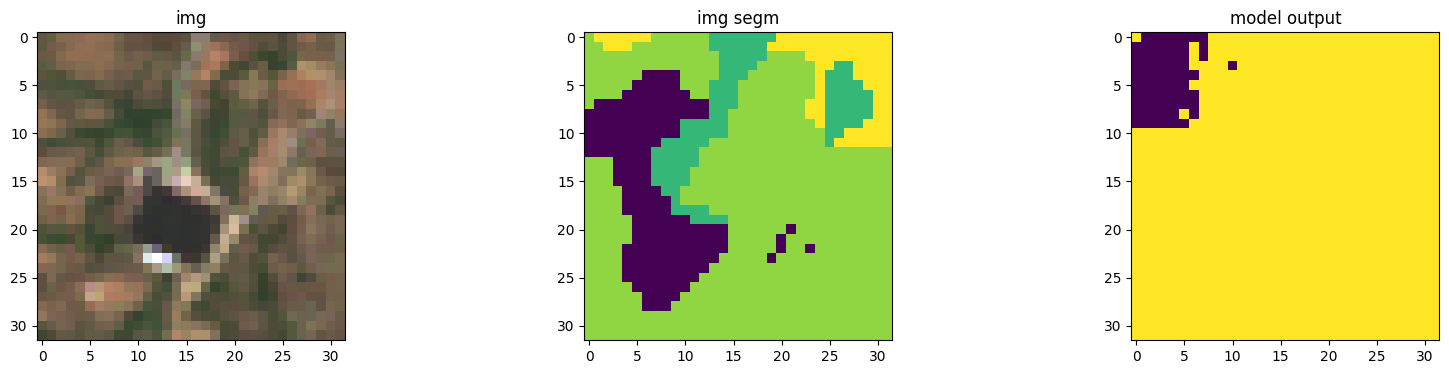

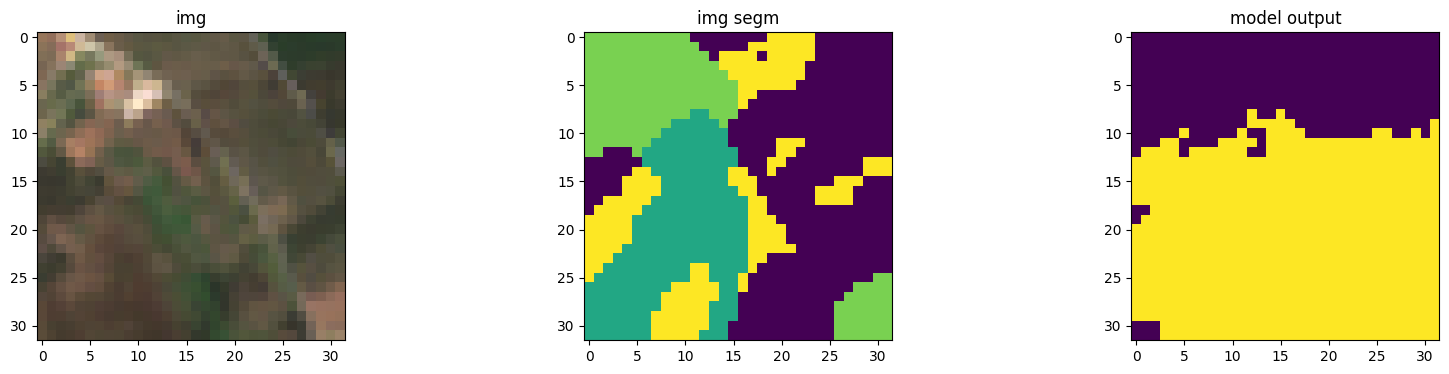

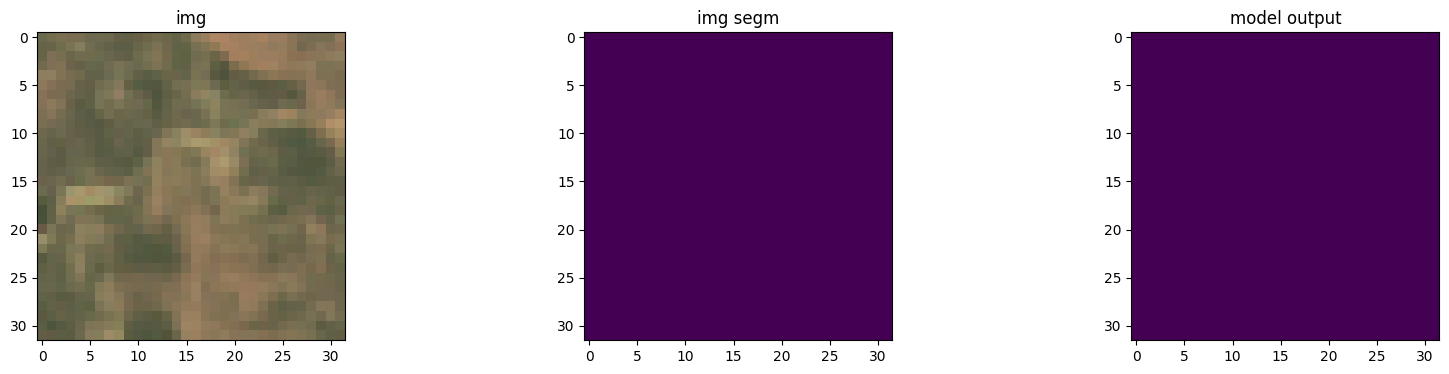

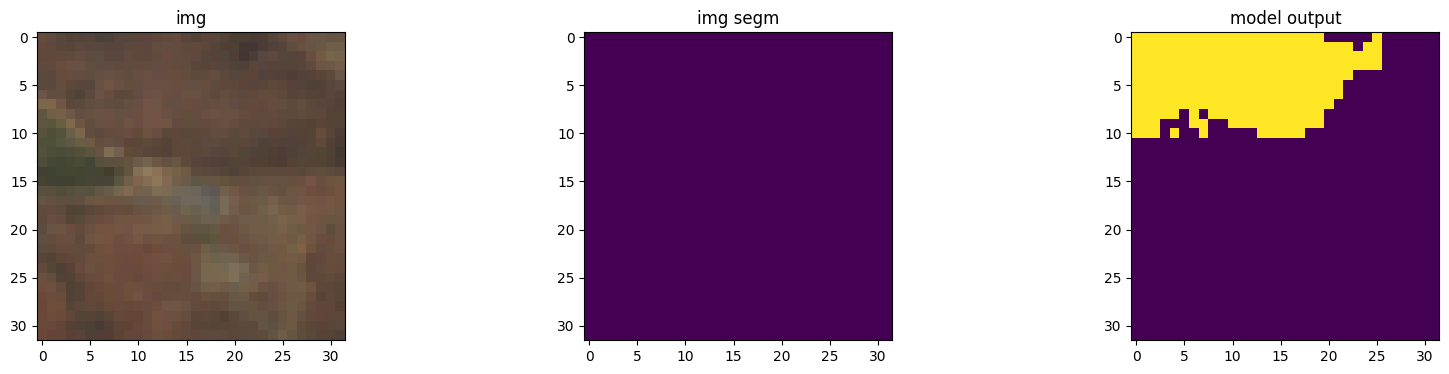

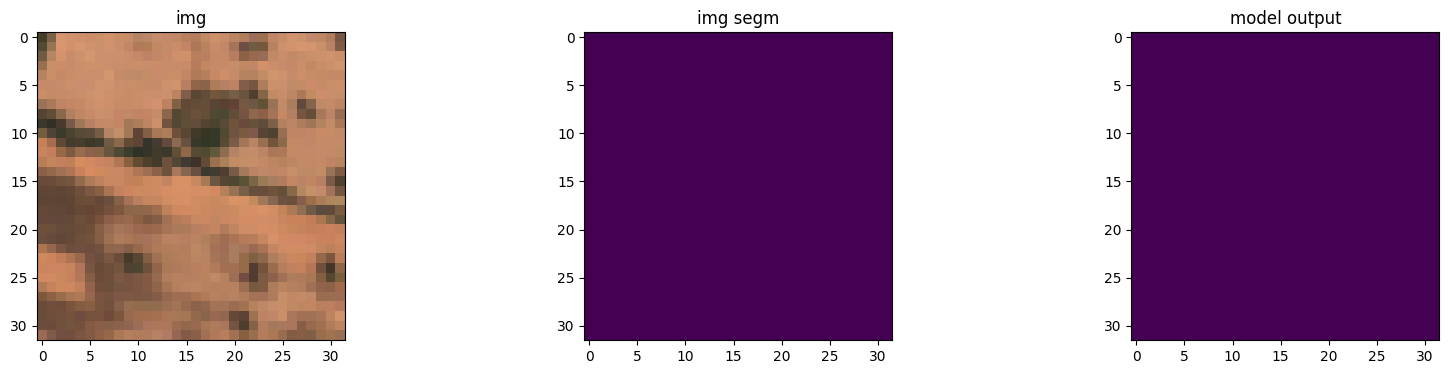

In [11]:
imgs, imgs_segm = next(iter(train_loader))
imgs_segm = imgs_to_niveaucouleur(imgs_segm)
output = model(imgs.to(device))
output = output.argmax(dim=1).cpu()  # prendre la classe avec la probabilité la plus élevée

for i in range(5):
    plt.figure(figsize=(20, 4))
    plt.subplot(1, 3, 1)
    plt.imshow((imgs[i].permute(1, 2, 0)+1)/2)
    plt.title("img")
    plt.subplot(1, 3, 2)
    plt.imshow(imgs_segm[i])
    plt.title("img segm")
    plt.subplot(1, 3, 3)
    plt.imshow(output[i])
    plt.title("model output")
    plt.show()

: 